In [ ]:
import pandas as pd; import numpy as np ; import matplotlib.pyplot as plt ; import seaborn as sns;
from numpy import argmax;
import scipy.stats as st;

from sklearn.datasets import make_classification as mc;
from sklearn.datasets import make_regression as mr
from sklearn.datasets import load_iris;
from sklearn.datasets import load_diabetes
from sklearn.datasets import load_breast_cancer
from sklearn.datasets import fetch_openml

from sklearn.metrics import precision_recall_curve as prc;
from sklearn.metrics import roc_curve as roc;
from sklearn.metrics import classification_report;
from sklearn.metrics import roc_auc_score;
from sklearn.metrics import precision_score;
from sklearn.metrics import recall_score;
from sklearn.metrics import get_scorer_names
from sklearn.metrics import f1_score as f1
from sklearn.metrics import accuracy_score as accuracy
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error as MSE

from sklearn.linear_model import LogisticRegression as LR;
from sklearn.linear_model import LinearRegression as LinReg;
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.linear_model import SGDClassifier as SGDC;

from sklearn.model_selection import train_test_split;
from sklearn.model_selection import cross_validate;
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold;
from sklearn.model_selection import LearningCurveDisplay
from sklearn.model_selection import RandomizedSearchCV as RSCV;
from sklearn.model_selection import LeavePOut;
from sklearn.model_selection import GridSearchCV as GSCV;

from sklearn.feature_selection import RFE
from sklearn.feature_selection import VarianceThreshold
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2
from sklearn.feature_selection import f_regression
from sklearn.feature_selection import mutual_info_regression
from sklearn.feature_selection import f_classif
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import SelectFromModel

from sklearn.neighbors import KNeighborsRegressor as KNNR
from sklearn.neighbors import KNeighborsClassifier as KNNC

from sklearn.gaussian_process import GaussianProcessClassifier as GPC
from sklearn.gaussian_process.kernels import RBF

from sklearn.preprocessing import OneHotEncoder as OHE;
from sklearn.preprocessing import StandardScaler as SC;
from sklearn.preprocessing import label_binarize
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.preprocessing import LabelEncoder

from sklearn.ensemble import RandomForestClassifier as RFC;
from sklearn.ensemble import RandomForestRegressor as RFR;
from sklearn.ensemble import GradientBoostingClassifier as GBC
from sklearn.ensemble import ExtraTreesClassifier as ETC;
from sklearn.ensemble import ExtraTreesRegressor as ETR;
from sklearn.ensemble import AdaBoostClassifier as AdaBoost;
from sklearn.ensemble import AdaBoostRegressor;
from sklearn.ensemble import GradientBoostingRegressor as GBR;

from sklearn.tree import DecisionTreeClassifier as DTC;
from sklearn.tree import DecisionTreeRegressor  as DTR
from sklearn.tree import plot_tree

from sklearn.naive_bayes import GaussianNB as GNB;

from sklearn.svm import SVC;
from sklearn.svm import SVR;

from sklearn.neural_network import MLPClassifier as MLPC
from sklearn.neural_network import MLPRegressor as MLPR;

from sklearn.utils.class_weight import compute_class_weight

from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import ADASYN
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import BorderlineSMOTE

from imblearn.under_sampling import RandomUnderSampler
from imblearn.under_sampling import NearMiss
from imblearn.under_sampling import TomekLinks
from imblearn.under_sampling import EditedNearestNeighbours


from yellowbrick.classifier import ROCAUC;
from yellowbrick.classifier import PrecisionRecallCurve;

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA;

from yellowbrick.model_selection import LearningCurve

from sklearn.pipeline import make_pipeline;

from tqdm.notebook import tqdm

import warnings;warnings.simplefilter("ignore")

# 1. Исследуйте связь между количеством самых важных признаков, которые использует модель для обучения и тестовой точностью получившейся модели. Обучите несколько моделей с разным количеством наиболее важных признаков. Постройте график зависимости точности модели от количества признаков. Сделайте вывод.

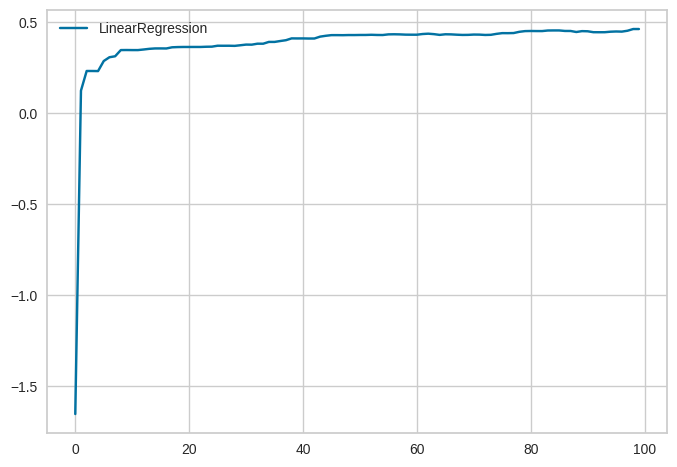

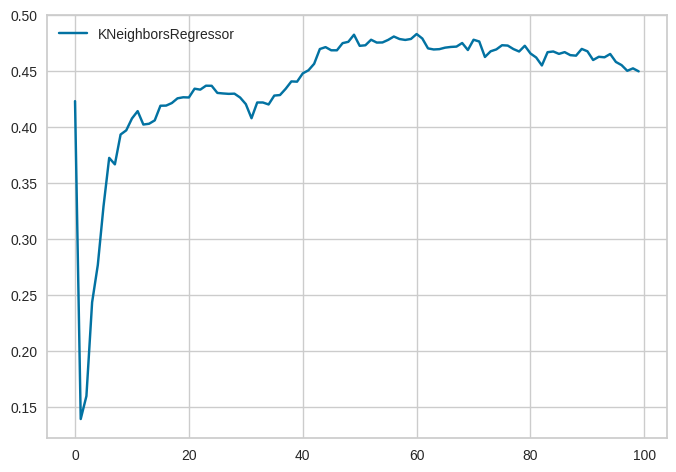

In [ ]:
df = fetch_openml("mtp", version=1, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(df.data, df.target, test_size=0.25, random_state=42)

rf = RFR(n_estimators=15).fit(X_train, y_train)
sort = rf.feature_importances_.argsort()

def compute(dff, sort, n, models):
    d = {i.__class__.__name__: [] for i in models}
    for model in models:
        for j in range(n):
            # Выбираем n самых важных признаков
            selected_features = dff.data.columns[sort][-j:]
            X = dff.data[selected_features]
            y = dff.target

            X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
            model.fit(X_train, y_train)
            d[model.__class__.__name__].append(model.score(X_test, y_test))
    return pd.DataFrame(d)

models = [LinReg(), KNNR()]
results = compute(df, sort, 100, models)
for i in results:
  plt.plot(results[i], label=i)
  plt.legend()
  plt.show()

# 2.Используйте другие методы отбора признаков: Исключение низкодисперсных признаков; Исключение по парным стаистическим критериям (хи-квадрат, тест Фишера, коэффициент корреляции, информационный критерий); Рекурсивное исключение признаков; Последовательное включение признаков; Исключение по L1-норме (гребневой регрессии).

In [ ]:
df = fetch_openml("mtp", version=1, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(df.data, df.target, test_size=0.25, random_state=42)
initial = pd.DataFrame(X_train).columns
iris = load_iris()
X2_train, X2_test, y2_train, y2_test = train_test_split(iris.data, iris.target, test_size=0.25, random_state=42)
initial2 = pd.DataFrame(X2_train).columns


#Исключение низкодисперсных признаков;

thr = 0.02
print("Дисперсия не ниже:",thr)
selector = VarianceThreshold(threshold=thr)
selector.fit(X_train)
mask = selector.get_support() # массив из true/false
selected_features = X_train.loc[:, mask]
print("Исходные данные:\n", initial)
print("\nВыбранные признаки:\n", selected_features.columns)


print(f'\n\n')
#Исключение по парным стаистическим критериям

print(f'\nхи-квадрат')

selector = SelectKBest(score_func=chi2, k=2)  # Выберем 2 лучших признака
selector.fit(X2_train,y2_train)
mask = selector.get_support()
selected_features = pd.DataFrame(X2_train).iloc[:, mask]
print("Исходные данные:\n", initial2)
print("\nВыбранные признаки:\n", selected_features.columns)

print(f'\nтест Фишера')
selector = SelectKBest(score_func=f_regression, k=3)  # Выберем 3 лучших признака
selector.fit(X2_train, y2_train)
mask = selector.get_support()
selected_features = pd.DataFrame(X2_train).iloc[:, mask]
print("Исходные признаки:\n", initial2)
print("\nВыбранные признаки:\n", selected_features.columns)

print(f'\nкоэффициент корреляции')
selector = SelectKBest(score_func=f_regression, k=3)  # Используем f_regression для примера
selector.fit(X2_train, y2_train)
mask = selector.get_support()
selected_features = pd.DataFrame(X2_train).iloc[:, mask]
print("Исходные признаки:\n", initial2)
print("\nВыбранные признаки:\n", selected_features.columns)

print("\nИнформационный критерий ")
selector = SelectKBest(score_func=mutual_info_classif, k=3)
selector.fit(X2_train, y2_train)
mask = selector.get_support()
selected_features = pd.DataFrame(X2_train).iloc[:, mask]
print("Исходные признаки:\n", initial2)
print("\nВыбранные признаки:\n", selected_features.columns)


print(f'\n\n')
print("\nРекурсивное исключение признаков (RFE) - для MTP")
model = LinReg()
rfe = RFE(model, n_features_to_select=10)  # Выбираем 10 признаков
rfe.fit(X_train, y_train)
mask = rfe.support_
selected_features = pd.DataFrame(X_train, columns=initial).loc[:, mask].columns
print("Исходные данные:\n", initial)
print("\nВыбранные признаки:\n", selected_features)

print(f'\n\n')
print("Исключение по L1-норме (Lasso)")
scaler = SC()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
lasso = Lasso(alpha=0.01)
lasso.fit(X_train_scaled, y_train)
selector = SelectFromModel(lasso, prefit=True)
mask = selector.get_support()
selected_features = pd.DataFrame(X_train, columns=initial).iloc[:, mask].columns
print("Исходные данные:\n", initial)
print("\nВыбранные признаки:\n", selected_features)


Дисперсия не ниже: 0.02
Исходные данные:
 Index(['oz1', 'oz2', 'oz3', 'oz4', 'oz5', 'oz6', 'oz7', 'oz8', 'oz9', 'oz10',
       ...
       'oz193', 'oz194', 'oz195', 'oz196', 'oz197', 'oz198', 'oz199', 'oz200',
       'oz201', 'oz202'],
      dtype='object', length=202)

Выбранные признаки:
 Index(['oz5', 'oz6', 'oz8', 'oz9', 'oz12', 'oz15', 'oz16', 'oz20', 'oz24',
       'oz25', 'oz26', 'oz27', 'oz28', 'oz31', 'oz35', 'oz39', 'oz41', 'oz43',
       'oz45', 'oz47', 'oz53', 'oz55', 'oz56', 'oz61', 'oz67', 'oz69', 'oz70',
       'oz72', 'oz85', 'oz87', 'oz88', 'oz90', 'oz108', 'oz113', 'oz114',
       'oz129', 'oz130', 'oz131', 'oz138', 'oz144', 'oz188', 'oz201', 'oz202'],
      dtype='object')




хи-квадрат
Исходные данные:
 RangeIndex(start=0, stop=4, step=1)

Выбранные признаки:
 Index([2, 3], dtype='int64')

тест Фишера
Исходные признаки:
 RangeIndex(start=0, stop=4, step=1)

Выбранные признаки:
 Index([0, 2, 3], dtype='int64')

коэффициент корреляции
Исходные признаки:
 RangeIndex(s

# 3. Изучите возможности библиотеки imbalanced-learn. Примените на данном примере возможности данной библиотеки для оверсемплинга и андерсемплинга выборки.

In [ ]:
def calculate_logistic_regression_score(X_train, y_train, X_test, y_test):
    try:
        m = LR(random_state=42)
        m.fit(X_train, y_train)
        y_pred = m.predict(X_test)
        report = classification_report(y_test, y_pred)
        return report
    except Exception as e:
        print(f"Произошла ошибка {e}")
        return "Ошибка"

df = fetch_openml("balance-scale", version=1, as_frame=True)
X, y = df.data, df.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Соотношение классов до обработки:", y_train.value_counts(normalize=True))
print("Original Classification Report:\n", calculate_logistic_regression_score(X_train, y_train, X_test, y_test))

# RandomOverSampler: Случайно дублирует примеры из миноритарного класса, чтобы сбалансировать классы.
ros = RandomOverSampler(random_state=42)
X_train_ros, y_train_ros = ros.fit_resample(X_train, y_train)
print("RandomOverSampler - Соотношение классов после обработки:", y_train_ros.value_counts(normalize=True))
print("RandomOverSampler Classification Report:\n", calculate_logistic_regression_score(X_train_ros, y_train_ros, X_test, y_test))

# SMOTE: Создает синтетические примеры миноритарного класса, интерполируя между существующими примерами.
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("SMOTE - Соотношение классов после обработки:", y_train_smote.value_counts(normalize=True))
print("SMOTE Classification Report:\n", calculate_logistic_regression_score(X_train_smote, y_train_smote, X_test, y_test))

# ADASYN: Аналогичен SMOTE, но генерирует больше синтетических примеров в тех областях пространства признаков, где миноритарный класс сложнее всего изучить.
try:
    adasyn = ADASYN()
    X_train_adasyn, y_train_adasyn = adasyn.fit_resample(X_train, y_train)
    print("ADASYN - Соотношение классов после обработки:", y_train_adasyn.value_counts(normalize=True))
    print("ADASYN Classification Report:\n", calculate_logistic_regression_score(X_train_adasyn, y_train_adasyn, X_test, y_test))
except Exception as e:
    print(f"ADASYN не сработал: {e}")

# BorderlineSMOTE: Создает синтетические примеры только для тех примеров миноритарного класса, которые находятся "на границе", т.е. классифицируются как сложные для обучения.
try:
    borderline_smote = BorderlineSMOTE(random_state=42)
    X_train_bsmote, y_train_bsmote = borderline_smote.fit_resample(X_train, y_train)
    print("Borderline SMOTE - Соотношение классов после обработки:", y_train_bsmote.value_counts(normalize=True))
    print("Borderline SMOTE Classification Report:\n", calculate_logistic_regression_score(X_train_bsmote, y_train_bsmote, X_test, y_test))
except Exception as e:
    print(f"Borderline SMOTE не сработал: {e}")

print(f'\n\n\n')

# RandomUnderSampler: Случайно удаляет примеры из мажоритарного класса, чтобы сбалансировать классы.
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)
print("RandomUnderSampler - Соотношение классов после обработки:", y_train_rus.value_counts(normalize=True))
print("RandomUnderSampler Classification Report:\n", calculate_logistic_regression_score(X_train_rus, y_train_rus, X_test, y_test))

# NearMiss: Удаляет примеры из мажоритарного класса, которые находятся ближе всего к примерам миноритарного класса.  version=1 - сохраняет примеры мажоритарного класса, минимальное среднее расстояние до трех ближайших примеров миноритарного класса
nearmiss = NearMiss(version=1)
X_train_nearmiss, y_train_nearmiss = nearmiss.fit_resample(X_train, y_train)
print("NearMiss - Соотношение классов после обработки:", y_train_nearmiss.value_counts(normalize=True))
print("NearMiss Classification Report:\n", calculate_logistic_regression_score(X_train_nearmiss, y_train_nearmiss, X_test, y_test))

# TomekLinks: Удаляет пары примеров (Tomek links), где один пример принадлежит мажоритарному классу, а другой - миноритарному, и они являются ближайшими соседями друг друга.  Удаляет пример мажоритарного класса из пары
tomek_links = TomekLinks()
X_train_tomek, y_train_tomek = tomek_links.fit_resample(X_train, y_train)
print("TomekLinks - Соотношение классов после обработки:", y_train_tomek.value_counts(normalize=True))
print("TomekLinks Classification Report:\n", calculate_logistic_regression_score(X_train_tomek, y_train_tomek, X_test, y_test))

# EditedNearestNeighbours: Удаляет примеры, которые неправильно классифицированы своими k ближайшими соседями.
enn = EditedNearestNeighbours()
X_train_enn, y_train_enn = enn.fit_resample(X_train, y_train)
print("EditedNearestNeighbours - Соотношение классов после обработки:", y_train_enn.value_counts(normalize=True))
print("EditedNearestNeighbours Classification Report:\n", calculate_logistic_regression_score(X_train_enn, y_train_enn, X_test, y_test))

Соотношение классов до обработки: class
L    0.474359
R    0.450855
B    0.074786
Name: proportion, dtype: float64
Original Classification Report:
               precision    recall  f1-score   support

           B       0.00      0.00      0.00        14
           L       0.73      1.00      0.85        66
           R       1.00      0.87      0.93        77

    accuracy                           0.85       157
   macro avg       0.58      0.62      0.59       157
weighted avg       0.80      0.85      0.81       157

RandomOverSampler - Соотношение классов после обработки: class
B    0.333333
L    0.333333
R    0.333333
Name: proportion, dtype: float64
RandomOverSampler Classification Report:
               precision    recall  f1-score   support

           B       0.44      0.86      0.59        14
           L       0.97      0.92      0.95        66
           R       1.00      0.87      0.93        77

    accuracy                           0.89       157
   macro avg       

# 4. Исследуйте влияние дискретизации целевой переменной на качество модели. Используйте уже продемострированный подход - построение базовой модели (baseline) и сравнение модели после обработки данных с базовой. Проверьте разное количество категорий, а также разные стратегии группировки. Сделайте выводы. Обратите внимание, что после биннинга целевой переменной она стала категориальной. А значит, задача превратилась в задачу классификации.

In [ ]:
df = fetch_openml("CPMP-2015-regression", version=1, as_frame=True)
X = df.data
X.drop(["instance_id"], inplace=True, axis=1)
X = pd.get_dummies(X)
y = df.target

# Разделение данных
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Базовая модель (регрессия)
m = LinReg()
m.fit(X_train, y_train)
y_pred_lr = m.predict(X_test)
mse_lr = MSE(y_test, y_pred_lr)
print(f"MSE базовой модели: {mse_lr}")
print(f"R^2: {m.score(X_test,y_test)}\n")

# Функция для дискретизации и обучения классификатора
def bin_and_classify(X, y, n_bins, strategy):
    enc = KBinsDiscretizer(n_bins=n_bins, encode='ordinal', strategy=strategy)
    y_binned = enc.fit_transform(y.values.reshape(-1, 1)).flatten()

    X_train, X_test, y_train, y_test = train_test_split(X, y_binned, test_size=0.2, random_state=42)

    rf = RFC(random_state=42)
    rf.fit(X_train, y_train)
    score = rf.score(X_test, y_test)
    return score

# Исследование разных стратегий и количества категорий
bins = [3, 5, 10, 15, 30]
strategies = ['uniform', 'quantile', 'kmeans']

for n in bins:
    for s in strategies:
        score = bin_and_classify(X, y, n, s)
        print(f"Количество бинов: {n}, Стратегия: {s}, Точность: {score}")
    print()

MSE базовой модели: 301839.42157333705
R^2: 0.8861661701392229

Количество бинов: 3, Стратегия: uniform, Точность: 0.9360189573459715
Количество бинов: 3, Стратегия: quantile, Точность: 0.8578199052132701
Количество бинов: 3, Стратегия: kmeans, Точность: 0.9075829383886256

Количество бинов: 5, Стратегия: uniform, Точность: 0.9170616113744076
Количество бинов: 5, Стратегия: quantile, Точность: 0.7345971563981043
Количество бинов: 5, Стратегия: kmeans, Точность: 0.8957345971563981

Количество бинов: 10, Стратегия: uniform, Точность: 0.8886255924170616
Количество бинов: 10, Стратегия: quantile, Точность: 0.5853080568720379
Количество бинов: 10, Стратегия: kmeans, Точность: 0.8175355450236966

Количество бинов: 15, Стратегия: uniform, Точность: 0.8672985781990521
Количество бинов: 15, Стратегия: quantile, Точность: 0.5497630331753555
Количество бинов: 15, Стратегия: kmeans, Точность: 0.8199052132701422

Количество бинов: 30, Стратегия: uniform, Точность: 0.8009478672985783
Количество бино

# Дополнительные задания

# 1. Повторите приведенный в данной работе анализ полностью на другом датасете. Сделайте вывод.

In [ ]:
# Dataset 1: mtp (регрессия, отбор признаков)
def analyze_mtp(d):
    X = pd.DataFrame(d.data)
    y = pd.Series(d.target)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

    b = LinReg()
    b.fit(X_train, y_train)
    bs = b.score(X_test, y_test)
    print(f"MTP Baseline R^2: {bs}")

    rf = RFR(n_estimators=15).fit(X_train, y_train)
    s = rf.feature_importances_.argsort()

    X_trimmed = X.iloc[:, s[-20:]]

    X_train_trimmed, X_test_trimmed, y_train, y_test = train_test_split(X_trimmed, y, test_size=0.25, random_state=42)

    bb = LinReg()
    bb.fit(X_train_trimmed, y_train)
    bbs = bb.score(X_test_trimmed, y_test)
    print(f"MTP Trimmed R^2: {bbs}")

    sfm = SelectFromModel(RFR(n_estimators=15)).fit(X, y)
    X_trimmed_sfm = sfm.transform(X)

    X_train_sfm, X_test_sfm, y_train, y_test = train_test_split(X_trimmed_sfm, y, test_size=0.25, random_state=42)

    m = LinReg()
    m.fit(X_train_sfm, y_train)
    res = m.score(X_test_sfm, y_test)
    print(f"MTP SelectFromModel R^2: {res}")

def analyze_balance_scale(d):
    X = pd.DataFrame(d.data)
    y = pd.Series(d.target)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

    b = LR()
    b.fit(X_train, y_train)
    bs = b.score(X_test, y_test)
    print(f"Balance Scale Baseline Accuracy: {bs}")
    print(classification_report(y_test, b.predict(X_test)))

    cw = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
    cw_dict = dict(zip(np.unique(y_train), cw))

    w = LR(class_weight=cw_dict)
    w.fit(X_train, y_train)
    ws = w.score(X_test, y_test)
    print(f"Balance Scale Weighted Accuracy: {ws}")
    print(classification_report(y_test, w.predict(X_test)))

    X_train["target"] = y_train
    max_count = X_train["target"].value_counts().max()
    oversampled = X_train.copy()
    for cls in X_train["target"].unique():
        n_samples = max_count - (X_train["target"] == cls).sum()
        if n_samples > 0:
            oversample_cls = X_train[X_train["target"] == cls].sample(n=n_samples, replace=True, random_state=42)
            oversampled = pd.concat([oversampled, oversample_cls], ignore_index=True)

    y_train_os = oversampled["target"]
    X_train_os = oversampled.drop("target", axis=1)

    o = LR()
    o.fit(X_train_os, y_train_os)
    os = o.score(X_test, y_test)
    print(f"Balance Scale Oversampled Accuracy: {os}")
    print(classification_report(y_test, o.predict(X_test)))

# Dataset 3: CPMP-2015-regression (регрессия, дискретизация целевой переменной)
def analyze_cpmp(d):
    X = pd.DataFrame(d.data)
    X = pd.get_dummies(X)
    y = pd.Series(d.target)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

    kd = KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile")
    y_binned = kd.fit_transform(pd.DataFrame(y_train))

    b = LinReg()
    b.fit(X_train, y_binned.ravel())
    bs = b.score(X_test, kd.transform(pd.DataFrame(y_test)))
    print(f"CPMP Binned (Quantile) R^2: {bs}")


d1 = load_diabetes()
d2 = load_breast_cancer()
d3 = fetch_openml(name="diamonds", version=2, as_frame=True)

analyze_mtp(d1)
analyze_balance_scale(d2)
analyze_cpmp(d3)

MTP Baseline R^2: 0.4849058889476756
MTP Trimmed R^2: 0.4849058889476756
MTP SelectFromModel R^2: 0.5022804813485974
Balance Scale Baseline Accuracy: 0.958041958041958
              precision    recall  f1-score   support

           0       0.98      0.91      0.94        53
           1       0.95      0.99      0.97        90

    accuracy                           0.96       143
   macro avg       0.96      0.95      0.95       143
weighted avg       0.96      0.96      0.96       143

Balance Scale Weighted Accuracy: 0.951048951048951
              precision    recall  f1-score   support

           0       0.96      0.91      0.93        53
           1       0.95      0.98      0.96        90

    accuracy                           0.95       143
   macro avg       0.95      0.94      0.95       143
weighted avg       0.95      0.95      0.95       143

Balance Scale Oversampled Accuracy: 0.951048951048951
              precision    recall  f1-score   support

           0      

# 2. Используйте продвинутые алгоритмы дискретизации целевой переменной, например, CART.

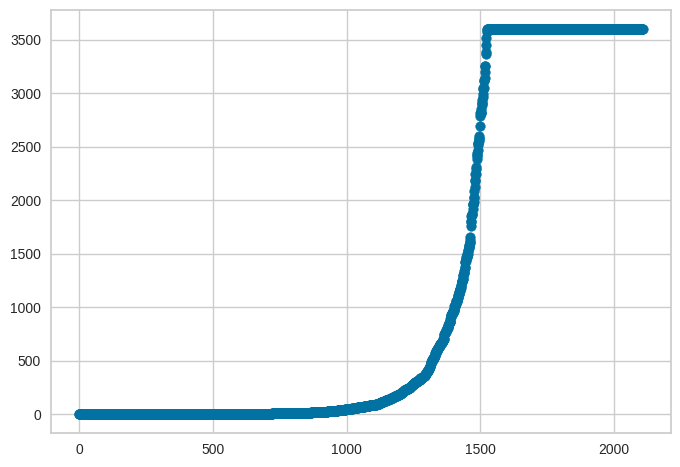

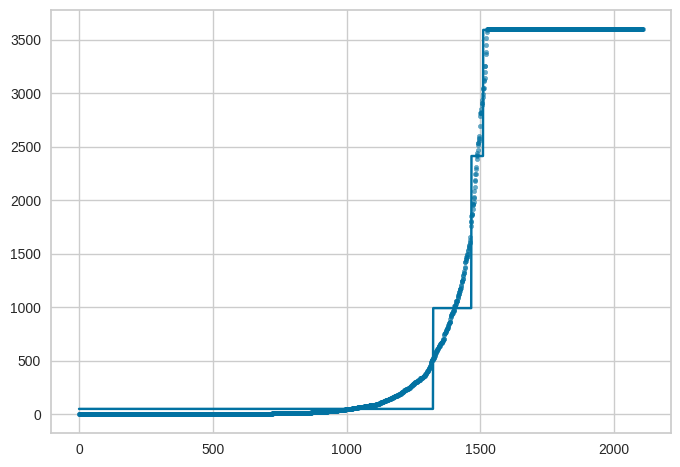

Accuracy: 0.8981042654028436
              precision    recall  f1-score   support

        48.0       0.88      0.99      0.93       248
       990.0       0.33      0.14      0.20        29
      2412.0       0.00      0.00      0.00        10
      3591.0       1.00      0.96      0.98       135

    accuracy                           0.90       422
   macro avg       0.55      0.52      0.53       422
weighted avg       0.86      0.90      0.87       422



In [ ]:
df = fetch_openml("CPMP-2015-regression", version=1,as_frame=True)
df.data.drop(["instance_id"], inplace=True, axis=1)
df.data = pd.get_dummies(df.data)
X = df.data
y = df.target
plt.scatter(np.arange(len(df.target)),sorted(df.target));plt.show()
m = DTR(max_depth=2)
sort_idx = np.argsort(y)
m.fit(np.arange(len(df.target)).reshape(-1,1),sorted(df.target))
plt.scatter(np.arange(len(df.target)),sorted(df.target),s=10,alpha=0.6);
plt.plot(np.arange(len(df.target)).reshape(-1,1),m.predict(np.arange(len(df.target)).reshape(-1,1)));plt.show()
p = pd.DataFrame(df.data).join(df.target)
p.loc[sort_idx,df.target.name]=np.int64(m.predict(np.arange(len(df.target)).reshape(-1,1)))
scaler = SC()
X_scaled = scaler.fit_transform(p.drop(df.target.name, axis=1)) #масштабируем только признаки
y_discrete = p[df.target.name]
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_discrete, test_size=0.2, random_state=42)

m = RFC()
m.fit(X_train, y_train)
accuracy = m.score(X_test, y_test)
print(f"Accuracy: {accuracy}")
print(classification_report(y_test,m.predict(X_test)))

# 3. Оформите алгоритм обработки данных как конвейер (pipeline) sklearn.

In [ ]:
df = fetch_openml("mtp", version=1)

X_train, X_test, y_train, y_test = train_test_split(df.data, df.target, test_size=0.25, random_state=42)

pipe = make_pipeline(
    SelectFromModel(RFR(n_estimators=15, random_state=42)),
    LinReg()
)

pipe.fit(X_train, y_train)

score = pipe.score(X_test, y_test)
print(score)

0.4255627552692838


# 4. Изучите и примените продвинутые стратегии оверсемплинга выборки: SMOTE, ASMO, ADASYN. Поясните механизм их работы и применимость в разных задачах.

In [ ]:
def calculate_logistic_regression_score(X_train, y_train, X_test, y_test):
    try:
        m = LR(random_state=42, multi_class='ovr')
        m.fit(X_train, y_train)
        y_pred = m.predict(X_test)
        report = classification_report(y_test, y_pred)
        return report
    except Exception as e:
        print(f"Произошла ошибка {e}")
        return "Ошибка"

# Загрузка датасета
df = fetch_openml("balance-scale", version=1, as_frame=True)
X, y = df.data, df.target

# Разделение на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Соотношение классов до обработки:", y_train.value_counts(normalize=True))
print("Original ROC AUC Score:", calculate_logistic_regression_score(X_train, y_train, X_test, y_test))

# SMOTE (Synthetic Minority Oversampling Technique)
# Описание:
#   * SMOTE создает синтетические примеры для миноритарного класса.
#   * Для каждого примера миноритарного класса выбирается k ближайших соседей.
#   * Синтетические примеры создаются путем интерполяции между исходным примером и его соседями.
# Применимость:
#   * Хорошо работает, когда миноритарный класс лежит в определенной области признакового пространства.
#   * Полезен, когда граница между классами не очень четкая.
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("\nSMOTE - Соотношение классов после обработки:", y_train_smote.value_counts(normalize=True))
print("SMOTE ROC AUC Score:", calculate_logistic_regression_score(X_train_smote, y_train_smote, X_test, y_test))

# ADASYN (Adaptive Synthetic Sampling Approach)
# Описание:
#   * ADASYN похож на SMOTE, но более адаптивен к трудным для классификации примерам.
#   * Он генерирует больше синтетических примеров для тех примеров миноритарного класса,
#     которые имеют больше соседей из мажоритарного класса (т.е. находятся в более "сложных" областях).
# Применимость:
#   * Полезен, когда граница между классами очень сложная и некоторые области миноритарного класса
#     окружены большим количеством примеров мажоритарного класса.
try:
    adasyn = ADASYN()
    X_train_adasyn, y_train_adasyn = adasyn.fit_resample(X_train, y_train)
    print("\nADASYN - Соотношение классов после обработки:", y_train_adasyn.value_counts(normalize=True))
    print("ADASYN ROC AUC Score:", calculate_logistic_regression_score(X_train_adasyn, y_train_adasyn, X_test, y_test))
except Exception as e:
    print(f"ADASYN не сработал: {e}")

# Borderline SMOTE (имитация ASMO)
# Описание:
#   * Borderline SMOTE генерирует синтетические примеры только вдоль "границы" между классами.
#   * Сначала определяются "пограничные" примеры миноритарного класса (те, у которых половина или более соседей - из мажоритарного класса).
#   * Затем SMOTE применяется только к этим пограничным примерам.
# Применимость:
#   * Полезен, когда нужно сфокусироваться на улучшении классификации на границе между классами,
#     не перегружая синтетическими примерами области, где классы уже хорошо разделены.
try:
    borderline_smote = BorderlineSMOTE(random_state=42)
    X_train_bsmote, y_train_bsmote = borderline_smote.fit_resample(X_train, y_train)
    print("\nBorderline SMOTE - Соотношение классов после обработки:", y_train_bsmote.value_counts(normalize=True))
    print("Borderline SMOTE ROC AUC Score:", calculate_logistic_regression_score(X_train_bsmote, y_train_bsmote, X_test, y_test))
except Exception as e:
    print(f"Borderline SMOTE не сработал: {e}")

Соотношение классов до обработки: class
L    0.474359
R    0.450855
B    0.074786
Name: proportion, dtype: float64
Original ROC AUC Score:               precision    recall  f1-score   support

           B       0.00      0.00      0.00        14
           L       0.73      1.00      0.85        66
           R       1.00      0.87      0.93        77

    accuracy                           0.85       157
   macro avg       0.58      0.62      0.59       157
weighted avg       0.80      0.85      0.81       157


SMOTE - Соотношение классов после обработки: class
B    0.333333
L    0.333333
R    0.333333
Name: proportion, dtype: float64
SMOTE ROC AUC Score:               precision    recall  f1-score   support

           B       0.36      0.71      0.48        14
           L       0.92      0.92      0.92        66
           R       1.00      0.82      0.90        77

    accuracy                           0.85       157
   macro avg       0.76      0.82      0.77       157
weight

# 5. Изучите и примените метод андерсемплинга выборки, основанный на Tomek Links. Сделайте вывод о его применимости к разным задачам.

In [ ]:
def calculate_logistic_regression_score(X_train, y_train, X_test, y_test):
    try:
        m = LR(random_state=42)
        m.fit(X_train, y_train)
        y_pred = m.predict(X_test)
        report = classification_report(y_test, y_pred)
        return report
    except Exception as e:
        print(f"Произошла ошибка {e}")
        return "Ошибка"

df = fetch_openml("balance-scale", version=1, as_frame=True)
X, y = df.data, df.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Соотношение классов до обработки:", y_train.value_counts(normalize=True))
print("Original Classification Report:\n", calculate_logistic_regression_score(X_train, y_train, X_test, y_test))


# TomekLinks: Удаляет пары примеров (Tomek links), где один пример принадлежит мажоритарному классу, а другой - миноритарному, и они являются ближайшими соседями друг друга.  Удаляет пример мажоритарного класса из пары
tomek_links = TomekLinks()
X_train_tomek, y_train_tomek = tomek_links.fit_resample(X_train, y_train)
print("TomekLinks - Соотношение классов после обработки:", y_train_tomek.value_counts(normalize=True))
print("TomekLinks Classification Report:\n", calculate_logistic_regression_score(X_train_tomek, y_train_tomek, X_test, y_test))


df = fetch_openml("wine_quality", version=1, as_frame=True)
X, y = df.data, df.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Соотношение классов до обработки:", y_train.value_counts(normalize=True))
print("Original Classification Report:\n", calculate_logistic_regression_score(X_train, y_train, X_test, y_test))


# TomekLinks: Удаляет пары примеров (Tomek links), где один пример принадлежит мажоритарному классу, а другой - миноритарному, и они являются ближайшими соседями друг друга.  Удаляет пример мажоритарного класса из пары
tomek_links = TomekLinks()
X_train_tomek, y_train_tomek = tomek_links.fit_resample(X_train, y_train)
print("TomekLinks - Соотношение классов после обработки:", y_train_tomek.value_counts(normalize=True))
print("TomekLinks Classification Report:\n", calculate_logistic_regression_score(X_train_tomek, y_train_tomek, X_test, y_test))


Соотношение классов до обработки: class
L    0.474359
R    0.450855
B    0.074786
Name: proportion, dtype: float64
Original Classification Report:
               precision    recall  f1-score   support

           B       0.00      0.00      0.00        14
           L       0.73      1.00      0.85        66
           R       1.00      0.87      0.93        77

    accuracy                           0.85       157
   macro avg       0.58      0.62      0.59       157
weighted avg       0.80      0.85      0.81       157

TomekLinks - Соотношение классов после обработки: class
L    0.473333
R    0.448889
B    0.077778
Name: proportion, dtype: float64
TomekLinks Classification Report:
               precision    recall  f1-score   support

           B       0.00      0.00      0.00        14
           L       0.74      1.00      0.85        66
           R       0.99      0.87      0.92        77

    accuracy                           0.85       157
   macro avg       0.58      0.62

# 6. Для датасета по классификации модифицируйте предсказание второй модели так, чтобы вернуть постановку задачи регрессии. Для этого каждой категории присвойте численное значение. Это можно сделать, вычислив, например, медиану. Теперь можно считать, что модель предсказывает не метку категории, а конкретное численное значение. Как следствие, для оценки такой модели можно использовать метрики качества регрессии. Сравните метрики до и после преобразования.

In [ ]:


# Загрузка датасета
df = fetch_openml("balance-scale", version=1, as_frame=True)
X = df.data
y = df.target

# Разделение данных на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# --- Задача классификации ---
print("\n--- Задача классификации ---")

# Обучение модели логистической регрессии
logreg_model = LR(random_state=42) # Явно указываем solver
logreg_model.fit(X_train, y_train)

# Предсказание классов
y_pred_class = logreg_model.predict(X_test)
# Оценка качества классификации
accuracy = accuracy(y_test, y_pred_class)
print(f"Accuracy: {accuracy}")
print("Classification Report:\n", classification_report(y_test, y_pred_class))


# --- Задача регрессии (с использованием LabelEncoder) ---
print("\n--- Задача регрессии (с LabelEncoder) ---")


label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)


linreg_model = LinReg()
linreg_model.fit(X_train, y_train_encoded)

y_pred_regression = linreg_model.predict(X_test)

mse = MSE(y_test_encoded, y_pred_regression)
r2 = r2_score(y_test_encoded, y_pred_regression)
print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2}")




--- Задача классификации ---
Accuracy: 0.8457446808510638
Classification Report:
               precision    recall  f1-score   support

           B       0.00      0.00      0.00        18
           L       0.75      1.00      0.86        80
           R       0.98      0.88      0.92        90

    accuracy                           0.85       188
   macro avg       0.57      0.63      0.59       188
weighted avg       0.79      0.85      0.81       188


--- Задача регрессии (с LabelEncoder) ---
Mean Squared Error: 0.2855289220011001
R-squared: 0.33255726063446545
